# ShopKart India — End-to-End Python Analytics

**Portfolio project | Indian B2C E-commerce Marketplace**

### Business problem
> How can ShopKart improve profitability and customer retention while reducing losses from excessive discounts, returns, and operational inefficiencies?

### Central question
> **Why isn't profitability improving despite sales growth?**

**Data disclosure:** ShopKart India is a synthetic India-context dataset created for portfolio analysis. 

## Notebook Roadmap

| Section | Purpose |
|---|---|
| 01 | Environment & Dataset Loading |
| 02 | Data Quality & Structural Analysis |
| 03 | Business KPI Overview |
| 04 | Time-Series & Growth Analysis |
| 05 | Profitability Analysis |
| 06 | Discount Effectiveness |
| 07 | Customer & RFM Analytics |
| 08 | Returns & Refund Analysis |
| 09 | Integrated Business Diagnosis |
| 10 | Statistical Analysis |
| 11 | Portfolio Visualizations |
| 12 | Final Business Findings |

**Principle:** flag unusual observations before deciding whether they are errors. Do not automatically delete business outliers.


## 01. Environment & Dataset Loading

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Environment ready.")


Environment ready.


In [2]:
# Locate the data folder. Works when the notebook is opened from
# either the project root or the project/python folder.

candidates = [
    Path("shopkart dataset"),
    Path("data"),
    Path.cwd().parent / "data",
    Path.cwd() / "data"
]

DATA_PATH = next((p.resolve() for p in candidates if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find the data folder. Put the five processed CSVs in ../data/."
    )

OUTPUT_PATH = DATA_PATH.parent / "outputs"
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

print("Data:", DATA_PATH)
print("Outputs:", OUTPUT_PATH)


Data: C:\Users\sneha\shopkart dataset
Outputs: C:\Users\sneha\outputs


In [3]:
order_items = pd.read_csv(DATA_PATH / "shopkart_order_item_analysis.csv")
monthly = pd.read_csv(DATA_PATH / "shopkart_monthly_performance.csv")
rfm = pd.read_csv(DATA_PATH / "shopkart_customer_rfm.csv")
products = pd.read_csv(DATA_PATH / "shopkart_product_performance.csv")
returns = pd.read_csv(DATA_PATH / "shopkart_returns.csv")

order_items["order_date"] = pd.to_datetime(order_items["order_date"], errors="coerce")
monthly["month"] = pd.to_datetime(monthly["month"], errors="coerce")
returns["return_date"] = pd.to_datetime(returns["return_date"], errors="coerce")

print("All five processed datasets loaded.")


All five processed datasets loaded.


In [4]:
datasets = {
    "Order Item Analysis": order_items,
    "Monthly Performance": monthly,
    "Customer RFM": rfm,
    "Product Performance": products,
    "Returns": returns
}

inventory = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Rows": [len(x) for x in datasets.values()],
    "Columns": [x.shape[1] for x in datasets.values()],
    "Missing Cells": [int(x.isna().sum().sum()) for x in datasets.values()],
    "Duplicate Rows": [int(x.duplicated().sum()) for x in datasets.values()]
})

inventory


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Order Item Analysis,324306,39,0,0
1,Monthly Performance,48,9,0,0
2,Customer RFM,27105,9,0,0
3,Product Performance,4917,10,0,0
4,Returns,27881,17,0,0


In [5]:
print("Main transaction dataset:", order_items.shape)
display(order_items.head())

cardinality = pd.Series({
    "Order-item rows": len(order_items),
    "Unique orders": order_items["order_id"].nunique(),
    "Unique customers": order_items["customer_id"].nunique(),
    "Unique products": order_items["product_id"].nunique(),
    "Unique sellers": order_items["seller_id"].nunique(),
    "Unique categories": order_items["category_name"].nunique()
})
display(cardinality.to_frame("Count"))


Main transaction dataset: (324306, 39)


,order_id,order_date,order_status,order_channel,customer_id,gender,date_of_birth,customer_segment,acquisition_channel,customer_location_id,customer_city,customer_state,customer_region,customer_city_tier,product_id,product_name,brand,category_id,category_name,subcategory_name,seller_id,seller_name,seller_type,fulfillment_type,seller_rating,order_item_id,quantity,unit_list_price,unit_selling_price,discount_percent,discount_amount,product_cost,item_revenue,item_cost,item_profit,profit_margin_percent,gross_merchandise_value,calculated_discount_percent,customer_order_number
0,ORD00147744,2023-07-13,Delivered,Mobile App,CUST000001,Female,1975-04-25,Premium,Organic Search,LOC114,Berhampur,Odisha,East,Tier 3,PROD002708,Omega Digital Headphones 203,Omega Digital,CAT004,Electronics,Headphones,SELLER0430,Divya Merchandise,Brand,Seller Fulfilled,4.00,ITEM00319438,1,"1,069.00","1,036.00",3.09,33.00,967.77,"1,036.00",967.77,68.23,6.59,"1,069.00",3.09,1
1,ORD00023541,2023-07-22,Delivered,Website,CUST000001,Female,1975-04-25,Premium,Organic Search,LOC114,Berhampur,Odisha,East,Tier 3,PROD004430,Livara Home Decorative Vase 889,Livara Home,CAT022,Home & Kitchen,Home Decor,SELLER0338,Pioneer Collections,Brand,Seller Fulfilled,3.90,ITEM00050721,1,"1,119.00","1,024.00",8.49,95.00,907.96,"1,024.00",907.96,116.04,11.33,"1,119.00",8.49,2
2,ORD00023541,2023-07-22,Delivered,Website,CUST000001,Female,1975-04-25,Premium,Organic Search,LOC114,Berhampur,Odisha,East,Tier 3,PROD003299,Metrostyle Nehru Jacket 972,Metrostyle,CAT019,Fashion,Ethnic Wear,SELLER0009,Urban Collections,Small Business,Seller Fulfilled,2.50,ITEM00050722,1,"3,409.00","2,028.00",40.51,"1,381.00","2,132.42","2,028.00","2,132.42",-104.42,-5.15,"3,409.00",40.51,3
3,ORD00057217,2024-09-30,Delivered,Mobile App,CUST000001,Female,1975-04-25,Premium,Organic Search,LOC114,Berhampur,Odisha,East,Tier 3,PROD004712,Cucina Casa Decorative Vase 214,Cucina Casa,CAT022,Home & Kitchen,Home Decor,SELLER0419,National Traders,Manufacturer,Seller Fulfilled,4.10,ITEM00123222,1,"1,149.00",696.00,39.43,453.00,747.58,696.00,747.58,-51.58,-7.41,"1,149.00",39.43,4
4,ORD00057217,2024-09-30,Delivered,Mobile App,CUST000001,Female,1975-04-25,Premium,Organic Search,LOC114,Berhampur,Odisha,East,Tier 3,PROD002473,Vasstra Innerwear Set 334,Vasstra,CAT018,Fashion,Innerwear,SELLER0446,Zephyr Traders,Retailer,Seller Fulfilled,3.10,ITEM00123221,2,"1,079.00",901.00,16.50,356.00,605.67,"1,802.00","1,211.34",590.66,32.78,"2,158.00",16.50,5


,Count
Order-item rows,324306
Unique orders,150000
Unique customers,27105
Unique products,4917
Unique sellers,500
Unique categories,6


## 02. Data Quality & Structural Analysis

In [6]:
quality = pd.DataFrame({
    "Dataset": list(datasets.keys()),
    "Rows": [len(x) for x in datasets.values()],
    "Missing Cells": [int(x.isna().sum().sum()) for x in datasets.values()],
    "Duplicate Rows": [int(x.duplicated().sum()) for x in datasets.values()]
})
display(quality)


,Dataset,Rows,Missing Cells,Duplicate Rows
0,Order Item Analysis,324306,0,0
1,Monthly Performance,48,0,0
2,Customer RFM,27105,0,0
3,Product Performance,4917,0,0
4,Returns,27881,0,0


In [7]:
# Detailed missing-value report
missing_rows = []
for name, df in datasets.items():
    for col, n in df.isna().sum().items():
        if n > 0:
            missing_rows.append({
                "Dataset": name,
                "Column": col,
                "Missing": int(n),
                "Missing %": n / len(df) * 100
            })

missing_report = pd.DataFrame(missing_rows)
if missing_report.empty:
    print("No missing values in the five processed datasets.")
else:
    display(missing_report.sort_values("Missing", ascending=False))


No missing values in the five processed datasets.


In [8]:
date_quality = pd.DataFrame({
    "Dataset": ["Order Items", "Monthly Performance", "Returns"],
    "Min Date": [
        order_items["order_date"].min(),
        monthly["month"].min(),
        returns["return_date"].min()
    ],
    "Max Date": [
        order_items["order_date"].max(),
        monthly["month"].max(),
        returns["return_date"].max()
    ],
    "Invalid Dates": [
        int(order_items["order_date"].isna().sum()),
        int(monthly["month"].isna().sum()),
        int(returns["return_date"].isna().sum())
    ]
})
date_quality


,Dataset,Min Date,Max Date,Invalid Dates
0,Order Items,2022-01-01,2025-12-31,0
1,Monthly Performance,2022-01-01,2025-12-01,0
2,Returns,2022-01-07,2026-02-10,0


In [9]:
numeric_columns = [
    "quantity", "unit_list_price", "unit_selling_price",
    "discount_percent", "discount_amount", "product_cost",
    "item_revenue", "item_cost", "item_profit",
    "profit_margin_percent", "gross_merchandise_value",
    "calculated_discount_percent"
]

numeric_profile = order_items[numeric_columns].describe().T
numeric_profile["negative_values"] = [
    int((order_items[c] < 0).sum()) for c in numeric_columns
]
numeric_profile["zero_values"] = [
    int((order_items[c] == 0).sum()) for c in numeric_columns
]
numeric_profile


,count,mean,std,min,25%,50%,75%,max,negative_values,zero_values
quantity,"324,306.00",1.44,0.82,1.00,1.00,1.00,2.00,5.00,0,0
unit_list_price,"324,306.00","4,618.23","14,706.53",109.00,589.00,979.00,"1,619.00","150,009.00",0,0
unit_selling_price,"324,306.00","4,166.13","13,666.21",50.00,454.00,788.00,"1,367.00","150,009.00",0,0
discount_percent,"324,306.00",16.94,13.40,0.00,6.31,14.47,25.54,72.31,0,40765
discount_amount,"324,306.00",605.98,"2,069.22",0.00,61.00,168.00,376.00,"83,136.00",0,40765
product_cost,"324,306.00","3,663.79","12,193.71",45.38,353.01,645.25,"1,182.44","131,026.62",0,0
item_revenue,"324,306.00","5,383.72","18,926.81",50.00,558.00,"1,007.00","1,922.00","425,145.00",0,0
item_cost,"324,306.00","4,719.85","16,859.27",45.38,446.32,816.77,"1,606.16","393,079.86",0,0
item_profit,"324,306.00",663.87,"2,559.99","-26,219.70",62.20,158.67,343.80,"79,630.86",37192,11
profit_margin_percent,"324,306.00",17.55,16.54,-128.83,7.74,16.79,28.79,65.97,37174,50


In [10]:
formula_checks = pd.DataFrame({
    "Check": [
        "Revenue = quantity × unit selling price",
        "Cost = quantity × product cost",
        "Profit = revenue - cost",
        "GMV = quantity × unit list price"
    ],
    "Rows failing": [
        int((~np.isclose(order_items["item_revenue"],
                         order_items["quantity"] * order_items["unit_selling_price"],
                         rtol=1e-5, atol=0.01)).sum()),
        int((~np.isclose(order_items["item_cost"],
                         order_items["quantity"] * order_items["product_cost"],
                         rtol=1e-5, atol=0.01)).sum()),
        int((~np.isclose(order_items["item_profit"],
                         order_items["item_revenue"] - order_items["item_cost"],
                         rtol=1e-5, atol=0.01)).sum()),
        int((~np.isclose(order_items["gross_merchandise_value"],
                         order_items["quantity"] * order_items["unit_list_price"],
                         rtol=1e-5, atol=0.01)).sum())
    ]
})
formula_checks


,Check,Rows failing
0,Revenue = quantity × unit selling price,0
1,Cost = quantity × product cost,0
2,Profit = revenue - cost,0
3,GMV = quantity × unit list price,0


In [11]:
# Check continuity of the monthly export
expected_months = pd.date_range(
    monthly["month"].min(),
    monthly["month"].max(),
    freq="MS"
)
missing_months = expected_months.difference(monthly["month"])

print("Expected months:", len(expected_months))
print("Actual months:", monthly["month"].nunique())
print("Missing months:", list(missing_months))


Expected months: 48
Actual months: 48
Missing months: []


In [12]:
# Return dates can legitimately occur after the order-data period.
order_max = order_items["order_date"].max()
return_max = returns["return_date"].max()

print("Order period:", order_items["order_date"].min().date(), "to", order_max.date())
print("Return period:", returns["return_date"].min().date(), "to", return_max.date())
print("Returns recorded after order-data period:", int((returns["return_date"] > order_max).sum()))


Order period: 2022-01-01 to 2025-12-31
Return period: 2022-01-07 to 2026-02-10
Returns recorded after order-data period: 366


In [13]:
status_distribution = (
    order_items["order_status"]
    .value_counts()
    .rename_axis("Order Status")
    .reset_index(name="Order-item Rows")
)
status_distribution["Share %"] = (
    status_distribution["Order-item Rows"] /
    status_distribution["Order-item Rows"].sum() * 100
)
status_distribution


,Order Status,Order-item Rows,Share %
0,Delivered,247302,76.26
1,Returned,62014,19.12
2,Cancelled,14858,4.58
3,In Transit,132,0.04


## 03. Business KPI Overview

In [14]:
kpis = pd.Series({
    "Orders": order_items["order_id"].nunique(),
    "Customers": order_items["customer_id"].nunique(),
    "Products": order_items["product_id"].nunique(),
    "Sellers": order_items["seller_id"].nunique(),
    "Units Sold": order_items["quantity"].sum(),
    "Revenue": order_items["item_revenue"].sum(),
    "Cost": order_items["item_cost"].sum(),
    "Profit": order_items["item_profit"].sum(),
    "Discount Value": order_items["discount_amount"].sum(),
    "Negative-profit Rows": (order_items["item_profit"] < 0).sum()
})
display(kpis.to_frame("Value"))

revenue = order_items["item_revenue"].sum()
profit = order_items["item_profit"].sum()
orders = order_items["order_id"].nunique()
customers = order_items["customer_id"].nunique()

derived = pd.Series({
    "Overall Profit Margin %": profit / revenue * 100,
    "Average Order Value": revenue / orders,
    "Revenue per Customer": revenue / customers,
    "Profit per Customer": profit / customers,
    "Discount as % of Revenue": order_items["discount_amount"].sum() / revenue * 100,
    "Negative-profit Row Share %": (order_items["item_profit"] < 0).mean() * 100
})
display(derived.to_frame("Value"))


,Value
Orders,"150,000.00"
Customers,"27,105.00"
Products,"4,917.00"
Sellers,500.00
Units Sold,"465,572.00"
Revenue,"1,745,972,433.00"
Cost,"1,530,676,901.56"
Profit,"215,295,531.44"
Discount Value,"196,521,825.00"
Negative-profit Rows,"37,192.00"


,Value
Overall Profit Margin %,12.33
Average Order Value,"11,639.82"
Revenue per Customer,"64,415.14"
Profit per Customer,"7,943.02"
Discount as % of Revenue,11.26
Negative-profit Row Share %,11.47


In [15]:
order_items["year"] = order_items["order_date"].dt.year

yearly_kpis = (
    order_items.groupby("year")
    .agg(
        orders=("order_id", "nunique"),
        customers=("customer_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        cost=("item_cost", "sum"),
        profit=("item_profit", "sum"),
        discount=("discount_amount", "sum")
    )
    .reset_index()
)

yearly_kpis["profit_margin_percent"] = yearly_kpis["profit"] / yearly_kpis["revenue"] * 100
yearly_kpis["revenue_growth_percent"] = yearly_kpis["revenue"].pct_change() * 100
yearly_kpis["profit_growth_percent"] = yearly_kpis["profit"].pct_change() * 100

yearly_kpis


,year,orders,customers,units_sold,revenue,cost,profit,discount,profit_margin_percent,revenue_growth_percent,profit_growth_percent
0,2022,22921,7034,70318,"325,777,401.00","284,037,374.78","41,740,026.22","34,247,851.00",12.81,NaN,NaN
1,2023,32346,11358,100806,"382,878,026.00","335,639,499.25","47,238,526.75","43,529,208.00",12.34,17.53,13.17
2,2024,43133,16041,134394,"504,674,061.00","442,830,241.00","61,843,820.00","55,558,415.00",12.25,31.81,30.92
3,2025,51600,19860,160054,"532,642,945.00","468,169,786.53","64,473,158.47","63,186,351.00",12.10,5.54,4.25


## 04. Time-Series & Growth Analysis

In [16]:
monthly = monthly.sort_values("month").copy()

monthly["revenue_growth_percent"] = monthly["revenue"].pct_change() * 100
monthly["profit_growth_percent"] = monthly["profit"].pct_change() * 100
monthly["orders_growth_percent"] = monthly["orders"].pct_change() * 100
monthly["revenue_3m_avg"] = monthly["revenue"].rolling(3).mean()
monthly["profit_3m_avg"] = monthly["profit"].rolling(3).mean()

annual_from_monthly = (
    monthly.assign(year=monthly["month"].dt.year)
    .groupby("year")
    .agg(
        orders=("orders", "sum"),
        customers=("customers", "sum"),
        units_sold=("units_sold", "sum"),
        revenue=("revenue", "sum"),
        cost=("cost", "sum"),
        profit=("profit", "sum"),
        discount=("discount", "sum")
    )
    .reset_index()
)

annual_from_monthly["profit_margin_percent"] = (
    annual_from_monthly["profit"] / annual_from_monthly["revenue"] * 100
)
annual_from_monthly["revenue_growth_percent"] = annual_from_monthly["revenue"].pct_change() * 100
annual_from_monthly["profit_growth_percent"] = annual_from_monthly["profit"].pct_change() * 100

display(annual_from_monthly)


,year,orders,customers,units_sold,revenue,cost,profit,discount,profit_margin_percent,revenue_growth_percent,profit_growth_percent
0,2022,22921,16754,70318,"325,777,401.00","284,037,374.78","41,740,026.22","34,247,851.00",12.81,NaN,NaN
1,2023,32346,25060,100806,"382,878,026.00","335,639,499.25","47,238,526.75","43,529,208.00",12.34,17.53,13.17
2,2024,43133,34370,134394,"504,674,061.00","442,830,241.00","61,843,820.00","55,558,415.00",12.25,31.81,30.92
3,2025,51600,41424,160054,"532,642,945.00","468,169,786.53","64,473,158.47","63,186,351.00",12.10,5.54,4.25


In [17]:
revenue_up_profit_down = monthly[
    (monthly["revenue"].diff() > 0) &
    (monthly["profit"].diff() < 0)
][[
    "month", "revenue", "profit",
    "revenue_growth_percent", "profit_growth_percent",
    "profit_margin_percent", "discount"
]]

print("Months where revenue increased while profit decreased:")
display(revenue_up_profit_down)

print("Top revenue months:")
display(monthly.nlargest(5, "revenue")[[
    "month", "revenue", "profit", "profit_margin_percent", "discount"
]])

print("Top profit months:")
display(monthly.nlargest(5, "profit")[[
    "month", "revenue", "profit", "profit_margin_percent", "discount"
]])


Months where revenue increased while profit decreased:


,month,revenue,profit,revenue_growth_percent,profit_growth_percent,profit_margin_percent,discount
26,2024-03-01,"40,960,212.00","5,314,717.14",2.17,-2.24,12.98,"3,914,976.00"


Top revenue months:


,month,revenue,profit,profit_margin_percent,discount
45,2025-10-01,"70,174,406.00","6,351,986.28",9.05,"11,278,164.00"
46,2025-11-01,"68,551,628.00","6,362,307.44",9.28,"10,948,834.00"
33,2024-10-01,"65,322,472.00","5,768,583.12",8.83,"9,948,474.00"
21,2023-10-01,"61,644,761.00","5,845,875.14",9.48,"8,618,317.00"
34,2024-11-01,"58,088,204.00","5,331,114.24",9.18,"8,693,479.00"


Top profit months:


,month,revenue,profit,profit_margin_percent,discount
46,2025-11-01,"68,551,628.00","6,362,307.44",9.28,"10,948,834.00"
45,2025-10-01,"70,174,406.00","6,351,986.28",9.05,"11,278,164.00"
36,2025-01-01,"47,579,826.00","6,226,429.58",13.09,"4,610,448.00"
24,2024-01-01,"46,253,985.00","6,153,082.58",13.30,"4,285,927.00"
21,2023-10-01,"61,644,761.00","5,845,875.14",9.48,"8,618,317.00"


### Time-series interpretation

Look for:
1. Revenue growth accompanied by profit growth.
2. Revenue growth accompanied by falling margin.
3. Periods where discount intensity rises faster than revenue.
4. Seasonal spikes that create volume but weaker contribution.
5. Whether the pattern is persistent or concentrated.

Do not label a period inefficient using revenue alone.


## 05. Profitability Analysis

In [18]:
products = products.copy()

loss_making_products = (
    products[products["profit"] < 0]
    .sort_values("profit")
)

revenue_threshold = products["revenue"].quantile(0.75)

high_revenue_low_margin = (
    products[
        (products["revenue"] >= revenue_threshold) &
        (products["profit_margin_percent"] < 5)
    ]
    .sort_values(["revenue", "profit"], ascending=[False, True])
)

print("Loss-making products:", len(loss_making_products))
display(loss_making_products.head(20))

print(f"75th-percentile revenue threshold: ₹{revenue_threshold:,.0f}")
display(high_revenue_low_margin.head(20))


Loss-making products: 79


,product_id,product_name,category_name,brand,units_sold,revenue,cost,profit,profit_margin_percent,total_discount
2723,PROD002767,Chic Route Sunglasses 927,Fashion,Chic Route,90,"88,957.00","99,545.40","-10,588.40",-11.90,"42,353.00"
3835,PROD003904,Nimbus Headphones 864,Electronics,Nimbus,2,"107,796.00","116,721.14","-8,925.14",-8.28,"23,782.00"
3260,PROD003310,Chic Route Women's Top 637,Fashion,Chic Route,191,"79,685.00","84,362.79","-4,677.79",-5.87,"30,904.00"
4623,PROD004703,Urbane Weave Backpack 115,Fashion,Urbane Weave,176,"135,604.00","138,944.96","-3,340.96",-2.46,"47,260.00"
4253,PROD004329,Cucina Casa Mixer Grinder 841,Home & Kitchen,Cucina Casa,11,"301,328.00","304,407.95","-3,079.95",-1.02,"89,491.00"
733,PROD000747,Nirvana Fits Thermal Wear 869,Fashion,Nirvana Fits,221,"442,555.00","445,248.70","-2,693.70",-0.61,"158,344.00"
2118,PROD002150,Nirvana Fits Innerwear Set 91,Fashion,Nirvana Fits,52,"45,599.00","48,233.64","-2,634.64",-5.78,"17,789.00"
3774,PROD003839,Quanta USB Hub 508,Electronics,Quanta,3,"126,621.00","128,622.60","-2,001.60",-1.58,"14,736.00"
3371,PROD003424,Nestwell Storage Box Set 743,Home & Kitchen,Nestwell,35,"23,997.00","25,796.75","-1,799.75",-7.50,"7,118.00"
1007,PROD001028,Cucina Casa Induction Cooktop 313,Home & Kitchen,Cucina Casa,69,"54,797.00","56,357.13","-1,560.13",-2.85,"14,824.00"


75th-percentile revenue threshold: ₹90,880


,product_id,product_name,category_name,brand,units_sold,revenue,cost,profit,profit_margin_percent,total_discount
3747,PROD003810,Omega Digital Tablet 524,Electronics,Omega Digital,390,"18,416,857.00","17,780,103.90","636,753.10",3.46,"1,316,753.00"
621,PROD000632,Quanta Laptop 347,Electronics,Quanta,150,"8,206,516.00","8,027,286.00","179,230.00",2.18,"763,334.00"
3258,PROD003308,Zentech Ink Cartridge Set 432,Electronics,Zentech,117,"6,300,460.00","6,093,853.74","206,606.26",3.28,"463,193.00"
987,PROD001008,Nexara Smartphone 556,Electronics,Nexara,85,"6,243,366.00","5,938,749.40","304,616.60",4.88,"536,149.00"
4533,PROD004612,Nexara Laptop 330,Electronics,Nexara,54,"3,948,911.00","3,824,365.32","124,545.68",3.15,"305,695.00"
289,PROD000294,Nimbus Smartphone 177,Electronics,Nimbus,63,"3,378,183.00","3,234,509.46","143,673.54",4.25,"351,354.00"
3817,PROD003886,Quanta Gaming Console 912,Electronics,Quanta,74,"3,262,231.00","3,116,816.36","145,414.64",4.46,"266,015.00"
1384,PROD001407,Arclight Laptop 575,Electronics,Arclight,122,"2,484,400.00","2,467,104.74","17,295.26",0.70,"186,058.00"
1321,PROD001344,Zentech Tablet 330,Electronics,Zentech,69,"2,449,943.00","2,430,381.48","19,561.52",0.80,"197,518.00"
3508,PROD003566,Nimbus Tablet 89,Electronics,Nimbus,1385,"1,799,699.00","1,719,837.60","79,861.40",4.44,"151,766.00"


In [19]:
category_profitability = (
    products.groupby("category_name")
    .agg(
        products=("product_id", "nunique"),
        units_sold=("units_sold", "sum"),
        revenue=("revenue", "sum"),
        cost=("cost", "sum"),
        profit=("profit", "sum"),
        discount=("total_discount", "sum")
    )
    .reset_index()
)

category_profitability["profit_margin_percent"] = (
    category_profitability["profit"] /
    category_profitability["revenue"] * 100
)

category_profitability["profit_contribution_percent"] = (
    category_profitability["profit"] /
    category_profitability["profit"].sum() * 100
)

display(category_profitability.sort_values("profit", ascending=False))


,category_name,products,units_sold,revenue,cost,profit,discount,profit_margin_percent,profit_contribution_percent
2,Electronics,1319,120491,"1,424,631,858.00","1,276,678,133.44","147,953,724.56","111,656,561.00",10.39,68.72
4,Home & Kitchen,990,98246,"159,438,451.00","131,515,053.23","27,923,397.77","34,628,073.00",17.51,12.97
3,Fashion,1296,156297,"120,268,871.00","93,288,548.20","26,980,322.80","42,657,292.00",22.43,12.53
0,Beauty & Personal Care,601,57732,"19,038,263.00","11,764,238.04","7,274,024.96","3,786,985.00",38.21,3.38
5,Sports & Fitness,357,15659,"17,006,772.00","12,947,227.19","4,059,544.81","3,343,789.00",23.87,1.89
1,Books & Stationery,354,17147,"5,588,218.00","4,483,701.46","1,104,516.54","449,125.00",19.77,0.51


In [20]:
seller_profitability = (
    order_items.groupby(["seller_id", "seller_name"])
    .agg(
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        cost=("item_cost", "sum"),
        profit=("item_profit", "sum"),
        discount=("discount_amount", "sum")
    )
    .reset_index()
)

seller_profitability["profit_margin_percent"] = (
    seller_profitability["profit"] /
    seller_profitability["revenue"] * 100
)

seller_profitability["profit_contribution_percent"] = (
    seller_profitability["profit"] /
    seller_profitability["profit"].sum() * 100
)

display(seller_profitability.sort_values("profit", ascending=False).head(20))


,seller_id,seller_name,orders,units_sold,revenue,cost,profit,discount,profit_margin_percent,profit_contribution_percent
220,SELLER0221,Aastha Creations,2283,2930,"130,853,986.00","109,310,071.18","21,543,914.82","9,915,134.00",16.46,10.01
394,SELLER0395,Sanskriti Home Store,1855,2336,"153,137,019.00","135,978,522.59","17,158,496.41","12,218,675.00",11.20,7.97
67,SELLER0068,Prime Traders,2166,2738,"42,441,438.00","36,641,474.57","5,799,963.43","3,289,794.00",13.67,2.69
421,SELLER0422,Royal Brands,557,725,"36,302,746.00","30,737,419.63","5,565,326.37","2,941,819.00",15.33,2.58
378,SELLER0379,Bharat Mart,1510,1949,"48,832,952.00","43,373,390.61","5,459,561.39","4,067,579.00",11.18,2.54
389,SELLER0390,Modern Distributors,831,1090,"40,603,514.00","35,775,898.12","4,827,615.88","3,188,316.00",11.89,2.24
85,SELLER0086,Sunrise Exports,1065,1336,"36,206,289.00","32,554,116.61","3,652,172.39","2,595,415.00",10.09,1.70
343,SELLER0344,Silver Emporium,966,1233,"38,294,197.00","34,735,182.60","3,559,014.40","2,954,280.00",9.29,1.65
336,SELLER0337,Vaibhav Retail,932,1171,"39,967,734.00","36,743,655.39","3,224,078.61","2,975,935.00",8.07,1.50
63,SELLER0064,Kalyan Overseas,1192,1468,"34,721,997.00","31,530,271.46","3,191,725.54","2,550,225.00",9.19,1.48


## 06. Discount Effectiveness

In [21]:
bins = [-0.01, 5, 10, 20, 30, 40, 50, 60, 100]
labels = ["0–5%", "5–10%", "10–20%", "20–30%",
          "30–40%", "40–50%", "50–60%", "60%+"]

order_items["discount_band"] = pd.cut(
    order_items["discount_percent"],
    bins=bins,
    labels=labels
)

discount_analysis = (
    order_items.groupby("discount_band", observed=False)
    .agg(
        order_items=("order_item_id", "nunique"),
        orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        profit=("item_profit", "sum"),
        discount=("discount_amount", "sum")
    )
    .reset_index()
)

discount_analysis["profit_margin_percent"] = (
    discount_analysis["profit"] /
    discount_analysis["revenue"] * 100
)

discount_analysis["revenue_share_percent"] = (
    discount_analysis["revenue"] /
    discount_analysis["revenue"].sum() * 100
)

discount_analysis


,discount_band,order_items,orders,units_sold,revenue,profit,discount,profit_margin_percent,revenue_share_percent
0,0–5%,68725,56393,94392,"658,454,886.00","112,543,834.87","10,073,822.00",17.09,37.71
1,5–10%,49246,42546,67801,"448,929,886.00","53,469,778.73","35,979,943.00",11.91,25.71
2,10–20%,88611,69084,128053,"462,777,647.00","37,936,813.61","75,399,120.00",8.20,26.51
3,20–30%,59919,50493,90274,"114,723,286.00","10,766,420.81","36,415,090.00",9.38,6.57
4,30–40%,35831,32364,53246,"41,987,748.00","2,608,754.74","22,011,396.00",6.21,2.40
5,40–50%,16528,15746,24056,"15,389,275.00","-1,045,038.71","12,193,609.00",-6.79,0.88
6,50–60%,4937,4861,7019,"3,433,719.00","-840,125.45","3,988,752.00",-24.47,0.20
7,60%+,509,505,731,"275,986.00","-144,907.16","460,093.00",-52.51,0.02


In [22]:
category_discount = (
    order_items.groupby(["category_name", "discount_band"], observed=False)
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        profit=("item_profit", "sum"),
        discount=("discount_amount", "sum")
    )
    .reset_index()
)

category_discount["profit_margin_percent"] = (
    category_discount["profit"] /
    category_discount["revenue"] * 100
)

display(category_discount.sort_values("profit", ascending=False).head(30))


,category_name,discount_band,units_sold,revenue,profit,discount,profit_margin_percent
16,Electronics,0–5%,48473,"609,019,922.00","95,052,051.99","9,592,985.00",15.61
17,Electronics,5–10%,34733,"412,714,509.00","42,442,879.94","32,967,608.00",10.28
18,Electronics,10–20%,33621,"365,839,175.00","13,328,212.68","58,113,464.00",3.64
34,Home & Kitchen,10–20%,31960,"53,915,862.00","10,873,461.42","9,577,998.00",20.17
26,Fashion,10–20%,32674,"28,958,948.00","9,414,205.60","5,245,108.00",32.51
32,Home & Kitchen,0–5%,14092,"27,567,249.00","8,685,369.20","299,579.00",31.51
27,Fashion,20–30%,40814,"31,814,986.00","7,533,596.30","10,587,490.00",23.68
33,Home & Kitchen,5–10%,11840,"21,404,950.00","5,697,073.30","1,779,160.00",26.62
24,Fashion,0–5%,12065,"12,287,432.00","5,182,698.21","95,423.00",42.18
35,Home & Kitchen,20–30%,25501,"37,706,046.00","3,876,683.32","12,301,763.00",10.28


In [23]:
high_discount_loss = (
    order_items[
        (order_items["discount_percent"] >= 30) &
        (order_items["item_profit"] < 0)
    ]
    .groupby(["product_id", "product_name", "category_name"])
    .agg(
        order_items=("order_item_id", "nunique"),
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        loss=("item_profit", "sum"),
        discount=("discount_amount", "sum")
    )
    .reset_index()
    .sort_values("loss")
)

display(high_discount_loss.head(25))


,product_id,product_name,category_name,order_items,units_sold,revenue,loss,discount
1239,PROD002787,Kitchcraft Steam Mop 9,Home & Kitchen,37,82,"1,085,567.00","-116,069.20","633,071.00"
1778,PROD004112,Livara Home Pressure Cooker 258,Home & Kitchen,38,49,"964,470.00","-80,705.88","549,581.00"
556,PROD001261,Nestwell Bookshelf 685,Home & Kitchen,60,78,"677,987.00","-78,057.64","389,755.00"
1697,PROD003894,Comfy Living Office Chair 880,Home & Kitchen,35,42,"683,916.00","-62,976.72","405,102.00"
1286,PROD002907,Weardrobe Ethnic Saree 150,Fashion,171,227,"314,316.00","-47,220.09","237,067.00"
668,PROD001521,Cozyloom Table Lamp 345,Home & Kitchen,10,15,"232,506.00","-42,718.95","114,879.00"
2101,PROD004909,Threadcraft Backpack 573,Fashion,292,364,"293,906.00","-41,086.84","251,730.00"
931,PROD002120,Threadcraft Digital Watch 832,Fashion,429,544,"228,849.00","-37,662.04","162,287.00"
341,PROD000747,Nirvana Fits Thermal Wear 869,Fashion,44,82,"131,415.00","-33,790.40","91,543.00"
1908,PROD004430,Livara Home Decorative Vase 889,Home & Kitchen,131,166,"119,072.00","-31,649.36","66,682.00"


### Discount interpretation

A high discount is not automatically ineffective. The business question is whether incremental volume/revenue compensates for the margin sacrificed.

This is observational analysis. It identifies patterns; it does not prove that discounts caused sales changes.


## 07. Customer & RFM Analytics

In [24]:
print("RFM shape:", rfm.shape)
display(rfm.head())
display(rfm.dtypes)


RFM shape: (27105, 9)


,customer_id,recency_days,frequency,monetary,total_profit,total_discount,recency_score,frequency_score,monetary_score
0,CUST034746,1459,1,"1,497.00",198.70,352.00,1,2,1
1,CUST015896,1458,1,"1,816.00",120.04,340.00,1,2,1
2,CUST047355,1455,1,"5,706.00","2,018.38","1,312.00",1,1,2
3,CUST014428,1452,1,"1,605.00",527.08,372.00,1,2,1
4,CUST008813,1452,1,"2,449.00",417.92,0.00,1,2,1


customer_id         object
recency_days         int64
frequency            int64
monetary           float64
total_profit       float64
total_discount     float64
recency_score        int64
frequency_score      int64
monetary_score       int64
dtype: object

In [25]:
# Create the final customer segment from the supplied 1–5 RFM scores.

def rfm_segment(row):
    r, f, m = row["recency_score"], row["frequency_score"], row["monetary_score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 4 and m >= 3:
        return "Loyal Customers"
    elif r >= 4 and f >= 2 and m >= 2:
        return "Potential Loyalists"
    elif r >= 4 and f <= 2:
        return "New / Promising"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost / Dormant"
    else:
        return "Needs Attention"

rfm["rfm_segment"] = rfm.apply(rfm_segment, axis=1)
rfm["rfm_score"] = (
    rfm["recency_score"].astype(str) +
    rfm["frequency_score"].astype(str) +
    rfm["monetary_score"].astype(str)
)

rfm["rfm_segment"].value_counts().to_frame("Customers")


,Customers
rfm_segment,
Champions,5145
Needs Attention,5129
At Risk,4682
Lost / Dormant,4509
Loyal Customers,3323
Potential Loyalists,2375
New / Promising,1942


In [26]:
rfm_segment_value = (
    rfm.groupby("rfm_segment")
    .agg(
        customers=("customer_id", "nunique"),
        revenue=("monetary", "sum"),
        profit=("total_profit", "sum"),
        discount=("total_discount", "sum"),
        avg_recency_days=("recency_days", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    )
    .reset_index()
)

rfm_segment_value["customer_share_percent"] = (
    rfm_segment_value["customers"] /
    rfm_segment_value["customers"].sum() * 100
)

rfm_segment_value["revenue_share_percent"] = (
    rfm_segment_value["revenue"] /
    rfm_segment_value["revenue"].sum() * 100
)

display(rfm_segment_value.sort_values("revenue", ascending=False))


,rfm_segment,customers,revenue,profit,discount,avg_recency_days,avg_frequency,avg_monetary,customer_share_percent,revenue_share_percent
1,Champions,5145,"1,103,004,760.00","135,066,475.91","122,096,253.00",40.93,17.09,"214,383.82",18.98,63.17
3,Loyal Customers,3323,"225,071,562.00","28,949,615.59","25,558,452.00",117.06,6.83,"67,731.44",12.26,12.89
0,At Risk,4682,"219,887,073.00","27,270,595.14","23,958,913.00",470.44,3.92,"46,964.35",17.27,12.59
4,Needs Attention,5129,"122,160,408.00","15,185,510.83","12,971,028.00",286.88,1.62,"23,817.59",18.92,7.00
6,Potential Loyalists,2375,"48,667,298.00","5,304,972.47","7,109,139.00",49.62,2.46,"20,491.49",8.76,2.79
5,New / Promising,1942,"16,472,507.00","1,671,082.64","2,591,898.00",51.08,1.03,"8,482.24",7.16,0.94
2,Lost / Dormant,4509,"10,708,825.00","1,847,278.86","2,236,142.00",566.87,1.08,"2,374.99",16.64,0.61


In [27]:
negative_customer_profit = rfm[rfm["total_profit"] < 0].sort_values("total_profit")

print("Customers with negative cumulative profit:", len(negative_customer_profit))
display(negative_customer_profit[[
    "customer_id", "recency_days", "frequency", "monetary",
    "total_profit", "total_discount", "rfm_segment"
]].head(20))


Customers with negative cumulative profit: 1218


,customer_id,recency_days,frequency,monetary,total_profit,total_discount,rfm_segment
19143,CUST024239,64,1,"71,423.00","-16,632.18","30,820.00",New / Promising
10891,CUST039889,232,4,"97,383.00","-16,296.29","49,400.00",Loyal Customers
19245,CUST015220,63,15,"231,213.00","-16,177.23","61,820.00",Champions
14701,CUST011485,129,2,"120,980.00","-15,494.53","35,996.00",Needs Attention
23754,CUST033946,31,2,"264,567.00","-14,906.22","59,152.00",Potential Loyalists
3956,CUST011295,541,3,"387,082.00","-14,820.74","75,025.00",At Risk
19315,CUST026725,63,1,"212,955.00","-14,718.80","63,880.00",New / Promising
5215,CUST016292,448,2,"70,802.00","-13,895.38","31,230.00",At Risk
22290,CUST021765,41,21,"154,024.00","-13,184.75","50,043.00",Champions
10243,CUST010896,251,6,"222,773.00","-13,180.63","67,113.00",At Risk


In [28]:
rfm_sorted = rfm.sort_values("monetary", ascending=False).copy()

for pct in [1, 5, 10]:
    n = max(1, int(len(rfm_sorted) * pct / 100))
    share = (
        rfm_sorted.head(n)["monetary"].sum() /
        rfm_sorted["monetary"].sum() * 100
    )
    print(f"Top {pct}% of customers: {share:.2f}% of monetary value")

at_risk_segments = ["At Risk", "Lost / Dormant"]
at_risk_value = (
    rfm[rfm["rfm_segment"].isin(at_risk_segments)]
    .agg(
        customers=("customer_id", "nunique"),
        revenue=("monetary", "sum"),
        profit=("total_profit", "sum"),
        discount=("total_discount", "sum")
    )
)

display(at_risk_value)

Top 1% of customers: 18.53% of monetary value
Top 5% of customers: 42.21% of monetary value
Top 10% of customers: 58.68% of monetary value


,customer_id,monetary,total_profit,total_discount
customers,"9,191.00",NaN,NaN,NaN
revenue,NaN,"230,595,898.00",NaN,NaN
profit,NaN,NaN,"29,117,874.00",NaN
discount,NaN,NaN,NaN,"26,195,055.00"


## 08. Returns & Refund Analysis

In [29]:
return_snapshot = pd.Series({
    "Return records": returns["return_id"].nunique(),
    "Orders with returns": returns["order_id"].nunique(),
    "Products returned": returns["product_id"].nunique(),
    "Refund amount": returns["refund_amount"].sum(),
    "Return cost": returns["return_cost"].sum(),
    "Refund + return cost": returns["refund_amount"].sum() + returns["return_cost"].sum()
})
display(return_snapshot.to_frame("Value"))

return_status = (
    returns["return_status"].value_counts()
    .rename_axis("Return Status")
    .reset_index(name="Returns")
)
return_status["Share %"] = return_status["Returns"] / return_status["Returns"].sum() * 100
display(return_status)

return_reason = (
    returns.groupby("return_reason")
    .agg(
        returns=("return_id", "nunique"),
        refund_amount=("refund_amount", "sum"),
        return_cost=("return_cost", "sum")
    )
    .reset_index()
)
return_reason["total_return_impact"] = (
    return_reason["refund_amount"] + return_reason["return_cost"]
)
display(return_reason.sort_values("returns", ascending=False))


,Value
Return records,"27,881.00"
Orders with returns,"25,581.00"
Products returned,"3,434.00"
Refund amount,"127,770,723.00"
Return cost,"25,432,195.86"
Refund + return cost,"153,202,918.86"


,Return Status,Returns,Share %
0,Refunded,20910,75.00
1,Approved,2784,9.99
2,Rejected,2249,8.07
3,Pending,1938,6.95


,return_reason,returns,refund_amount,return_cost,total_return_impact
6,Size/Fit Issue,5180,"7,103,994.00","1,628,306.30","8,732,300.30"
5,Product Quality Issue,4673,"27,296,346.00","5,476,034.54","32,772,380.54"
4,Product Not as Described,4386,"18,549,194.00","3,580,197.63","22,129,391.63"
1,Damaged Product,3658,"27,292,973.00","5,258,858.84","32,551,831.84"
0,Changed Mind,3411,"10,761,325.00","2,141,119.93","12,902,444.93"
7,Wrong Product,3088,"17,593,016.00","3,469,916.37","21,062,932.37"
2,Missing Item,1802,"10,390,470.00","2,043,894.20","12,434,364.20"
3,Other,1683,"8,783,405.00","1,833,868.05","10,617,273.05"


In [30]:
total_order_items = order_items["order_item_id"].nunique()
returned_order_items = returns["order_item_id"].nunique()

overall_return_rate = returned_order_items / total_order_items * 100

print(f"Order items: {total_order_items:,}")
print(f"Returned order items: {returned_order_items:,}")
print(f"Order-item return rate: {overall_return_rate:.2f}%")


Order items: 324,306
Returned order items: 27,881
Order-item return rate: 8.60%


In [31]:
category_return = (
    returns.groupby("category_name")
    .agg(
        returned_items=("order_item_id", "nunique"),
        return_records=("return_id", "nunique"),
        refund_amount=("refund_amount", "sum"),
        return_cost=("return_cost", "sum")
    )
    .reset_index()
)

category_units = (
    order_items.groupby("category_name")
    .agg(order_items=("order_item_id", "nunique"))
    .reset_index()
)

category_return = category_return.merge(category_units, on="category_name", how="left")

category_return["return_rate_percent"] = (
    category_return["returned_items"] /
    category_return["order_items"] * 100
)

category_return["total_return_impact"] = (
    category_return["refund_amount"] +
    category_return["return_cost"]
)

display(category_return.sort_values("return_rate_percent", ascending=False))


,category_name,returned_items,return_records,refund_amount,return_cost,order_items,return_rate_percent,total_return_impact
3,Fashion,13906,13906,"12,725,959.00","3,112,945.51",109720,12.67,"15,838,904.51"
2,Electronics,8190,8190,"105,946,718.00","20,391,580.81",96197,8.51,"126,338,298.81"
4,Home & Kitchen,3645,3645,"7,564,638.00","1,549,601.56",61858,5.89,"9,114,239.56"
5,Sports & Fitness,633,633,"812,223.00","168,967.67",12439,5.09,"981,190.67"
0,Beauty & Personal Care,1248,1248,"622,562.00","173,416.54",32532,3.84,"795,978.54"
1,Books & Stationery,259,259,"98,623.00","35,683.77",11560,2.24,"134,306.77"


In [32]:
product_units = (
    order_items.groupby(["product_id", "product_name", "category_name"])
    .agg(units_sold=("quantity", "sum"),
         order_items=("order_item_id", "nunique"))
    .reset_index()
)

product_returns = (
    returns.groupby(["product_id", "product_name", "category_name"])
    .agg(
        returned_items=("order_item_id", "nunique"),
        refund_amount=("refund_amount", "sum"),
        return_cost=("return_cost", "sum")
    )
    .reset_index()
)

product_return_analysis = product_units.merge(
    product_returns,
    on=["product_id", "product_name", "category_name"],
    how="left"
)

for col in ["returned_items", "refund_amount", "return_cost"]:
    product_return_analysis[col] = product_return_analysis[col].fillna(0)

product_return_analysis["return_rate_percent"] = (
    product_return_analysis["returned_items"] /
    product_return_analysis["order_items"] * 100
)

product_return_analysis["total_return_impact"] = (
    product_return_analysis["refund_amount"] +
    product_return_analysis["return_cost"]
)

high_volume_return_products = (
    product_return_analysis[
        product_return_analysis["order_items"] >= 50
    ]
    .sort_values("return_rate_percent", ascending=False)
)

display(high_volume_return_products.head(25))


,product_id,product_name,category_name,units_sold,order_items,returned_items,refund_amount,return_cost,return_rate_percent,total_return_impact
1555,PROD001579,Silkline Men's Jacket 608,Fashion,109,89,24.00,"11,908.00","3,540.49",26.97,"15,448.49"
1082,PROD001103,Silkline Sunglasses 613,Fashion,109,50,13.00,"7,936.00","2,001.30",26.00,"9,937.30"
3911,PROD003980,Pulsecore Smartwatch 780,Electronics,59,51,13.00,"9,248.00","2,669.93",25.49,"11,917.93"
3677,PROD003738,Weardrobe Wallet 975,Fashion,101,75,19.00,"38,165.00","8,133.82",25.33,"46,298.82"
4247,PROD004322,Threadcraft Nehru Jacket 422,Fashion,68,57,14.00,"22,990.00","4,548.94",24.56,"27,538.94"
1201,PROD001223,Fabrico Sunglasses 446,Fashion,208,95,23.00,"148,695.00","26,101.31",24.21,"174,796.31"
4180,PROD004254,Weardrobe Thermal Wear 226,Fashion,114,50,12.00,"14,300.00","3,841.14",24.00,"18,141.14"
32,PROD000033,Vasstra Wallet 806,Fashion,85,67,16.00,"6,371.00","2,197.87",23.88,"8,568.87"
2312,PROD002347,Weardrobe Women's Kurti 500,Fashion,140,116,27.00,"23,933.00","5,202.37",23.28,"29,135.37"
2695,PROD002737,Urbane Weave Sandals 297,Fashion,394,330,76.00,"77,236.00","16,689.23",23.03,"93,925.23"


In [33]:
seller_return = (
    returns.groupby(["seller_id", "seller_name"])
    .agg(
        returned_items=("order_item_id", "nunique"),
        refund_amount=("refund_amount", "sum"),
        return_cost=("return_cost", "sum")
    )
    .reset_index()
)

seller_units = (
    order_items.groupby(["seller_id", "seller_name"])
    .agg(order_items=("order_item_id", "nunique"))
    .reset_index()
)

seller_return = seller_return.merge(
    seller_units, on=["seller_id", "seller_name"], how="left"
)

seller_return["return_rate_percent"] = (
    seller_return["returned_items"] /
    seller_return["order_items"] * 100
)

seller_return["total_return_impact"] = (
    seller_return["refund_amount"] + seller_return["return_cost"]
)

display(seller_return.sort_values("total_return_impact", ascending=False).head(25))


,seller_id,seller_name,returned_items,refund_amount,return_cost,order_items,return_rate_percent,total_return_impact
218,SELLER0221,Aastha Creations,289,"13,962,266.00","2,400,288.93",2326,12.42,"16,362,554.93"
390,SELLER0395,Sanskriti Home Store,203,"13,047,986.00","2,439,169.89",1862,10.90,"15,487,155.89"
375,SELLER0379,Bharat Mart,174,"4,389,987.00","727,139.43",1518,11.46,"5,117,126.43"
340,SELLER0344,Silver Emporium,87,"3,861,178.00","700,505.86",967,9.00,"4,561,683.86"
386,SELLER0390,Modern Distributors,104,"3,541,691.00","788,407.17",832,12.50,"4,330,098.17"
84,SELLER0086,Sunrise Exports,107,"3,308,463.00","579,381.71",1067,10.03,"3,887,844.71"
333,SELLER0337,Vaibhav Retail,66,"2,808,057.00","506,866.16",935,7.06,"3,314,923.16"
62,SELLER0064,Kalyan Overseas,132,"2,615,845.00","532,918.58",1200,11.00,"3,148,763.58"
86,SELLER0088,Divya Home Store,56,"2,552,170.00","515,280.47",385,14.55,"3,067,450.47"
114,SELLER0117,Vikram Overseas,130,"2,458,298.00","511,872.94",1531,8.49,"2,970,170.94"


### Return-impact definition

**Direct return impact = refund amount + return cost**

This is not necessarily the final economic loss because returned goods may be recovered, restocked, repaired, resold, or written off.

Use both **return rate** and **return volume/financial impact** when prioritizing problems.


## 09. Integrated Business Diagnosis

In [34]:
product_core = (
    order_items.groupby(["product_id", "product_name", "category_name"])
    .agg(
        units_sold=("quantity", "sum"),
        revenue=("item_revenue", "sum"),
        cost=("item_cost", "sum"),
        profit=("item_profit", "sum"),
        discount=("discount_amount", "sum"),
        avg_discount_percent=("discount_percent", "mean")
    )
    .reset_index()
)

product_core["profit_margin_percent"] = (
    product_core["profit"] /
    product_core["revenue"] * 100
)

integrated_products = product_core.merge(
    product_return_analysis[
        ["product_id", "returned_items", "return_rate_percent", "total_return_impact"]
    ],
    on="product_id",
    how="left"
)

for col in ["returned_items", "return_rate_percent", "total_return_impact"]:
    integrated_products[col] = integrated_products[col].fillna(0)

integrated_products.head()


,product_id,product_name,category_name,units_sold,revenue,cost,profit,discount,avg_discount_percent,profit_margin_percent,returned_items,return_rate_percent,total_return_impact
0,PROD000001,Zentech Camera 315,Electronics,43,"43,704.00","37,581.14","6,122.86","3,123.00",6.58,14.01,0.00,0.00,0.00
1,PROD000002,Zentech Laptop Stand 315,Electronics,1066,"36,018,421.00","32,153,406.22","3,865,014.78","2,985,453.00",7.53,10.73,78.00,9.52,"3,606,265.17"
2,PROD000003,Radiance Rituals Body Wash 851,Beauty & Personal Care,107,"15,281.00","6,176.04","9,104.96","2,802.00",16.12,59.58,2.00,3.64,"1,337.18"
3,PROD000004,Bookhaven Colored Pencil Set 679,Books & Stationery,14,"5,486.00","4,949.56",536.44,520.00,10.02,9.78,0.00,0.00,0.00
4,PROD000005,Urbane Weave Sunglasses 581,Fashion,31,"33,268.00","27,066.72","6,201.28","11,651.00",26.69,18.64,3.00,25.00,"5,643.11"


In [35]:
eligible = integrated_products[integrated_products["units_sold"] >= 10].copy()

eligible["low_margin_flag"] = eligible["profit_margin_percent"] < 5
eligible["high_discount_flag"] = eligible["avg_discount_percent"] >= 30
eligible["high_return_flag"] = eligible["return_rate_percent"] >= 20
eligible["negative_profit_flag"] = eligible["profit"] < 0

eligible["business_risk_score"] = (
    eligible["low_margin_flag"].astype(int) +
    eligible["high_discount_flag"].astype(int) +
    eligible["high_return_flag"].astype(int) +
    eligible["negative_profit_flag"].astype(int)
)

risk_products = eligible.sort_values(
    ["business_risk_score", "revenue"],
    ascending=[False, False]
)

display(risk_products[[
    "product_id", "product_name", "category_name",
    "units_sold", "revenue", "profit", "profit_margin_percent",
    "avg_discount_percent", "return_rate_percent",
    "total_return_impact", "business_risk_score"
]].head(30))


,product_id,product_name,category_name,units_sold,revenue,profit,profit_margin_percent,avg_discount_percent,return_rate_percent,total_return_impact,business_risk_score
663,PROD000676,Denimo Sneakers 598,Fashion,11,"8,050.00",-300.10,-3.73,38.12,20.00,"1,502.90",4
2723,PROD002767,Chic Route Sunglasses 927,Fashion,90,"88,957.00","-10,588.40",-11.90,30.89,14.63,"17,631.86",3
4560,PROD004639,Silkline Thermal Wear 559,Fashion,50,"58,762.00",-552.00,-0.94,33.06,0.00,0.00,3
1233,PROD001255,Denimo Sandals 222,Fashion,45,"19,775.00",-126.25,-0.64,27.68,23.68,"5,749.92",3
1402,PROD001425,Fabrico Kids Shorts 126,Fashion,10,"15,290.00",395.90,2.59,31.71,25.00,"3,714.06",3
3669,PROD003730,Chic Route Kids Shorts 834,Fashion,31,"12,054.00",-124.35,-1.03,30.69,12.50,"1,830.57",3
4107,PROD004179,Weardrobe Men's Jeans 443,Fashion,12,"9,587.00",-76.96,-0.80,27.22,30.00,"3,157.47",3
2236,PROD002270,Silkline Wallet 819,Fashion,10,"5,103.00",-267.00,-5.23,32.77,10.00,478.42,3
772,PROD000788,Metrostyle Analog Watch 428,Fashion,10,"2,832.00",112.10,3.96,36.01,22.22,487.10,3
733,PROD000747,Nirvana Fits Thermal Wear 869,Fashion,221,"442,555.00","-2,693.70",-0.61,27.37,8.57,"54,109.47",2


In [36]:
risk_exposure = pd.DataFrame({
    "Metric": [
        "Eligible product revenue",
        "Eligible product profit",
        "Revenue from negative-profit products",
        "Revenue from <5% margin products",
        "Revenue from >=30% average-discount products",
        "Revenue from >=20% return-rate products",
        "Revenue from products with 3+ risk signals"
    ],
    "Value": [
        eligible["revenue"].sum(),
        eligible["profit"].sum(),
        eligible.loc[eligible["negative_profit_flag"], "revenue"].sum(),
        eligible.loc[eligible["low_margin_flag"], "revenue"].sum(),
        eligible.loc[eligible["high_discount_flag"], "revenue"].sum(),
        eligible.loc[eligible["high_return_flag"], "revenue"].sum(),
        eligible.loc[eligible["business_risk_score"] >= 3, "revenue"].sum()
    ]
})
risk_exposure


,Metric,Value
0,Eligible product revenue,"1,735,354,664.00"
1,Eligible product profit,"213,932,502.01"
2,Revenue from negative-profit products,"2,370,863.00"
3,Revenue from <5% margin products,"94,628,383.00"
4,Revenue from >=30% average-discount products,"2,456,120.00"
5,Revenue from >=20% return-rate products,"21,235,992.00"
6,Revenue from products with 3+ risk signals,"220,410.00"


In [37]:
monthly_diagnostic = monthly.copy()

monthly_diagnostic["discount_rate_percent"] = (
    monthly_diagnostic["discount"] /
    monthly_diagnostic["revenue"] * 100
)

monthly_diagnostic["profit_per_order"] = (
    monthly_diagnostic["profit"] /
    monthly_diagnostic["orders"]
)

monthly_diagnostic["revenue_per_order"] = (
    monthly_diagnostic["revenue"] /
    monthly_diagnostic["orders"]
)

display(monthly_diagnostic.sort_values("profit_margin_percent"))


,month,orders,customers,units_sold,revenue,cost,profit,profit_margin_percent,discount,revenue_growth_percent,profit_growth_percent,orders_growth_percent,revenue_3m_avg,profit_3m_avg,discount_rate_percent,profit_per_order,revenue_per_order
10,2022-11-01,3012,2138,9474,"40,343,001.00","36,827,017.07","3,515,983.93",8.72,"6,073,085.00",-2.73,-9.72,-7.66,"34,867,471.67","3,527,497.63",15.05,"1,167.33","13,394.09"
33,2024-10-01,5792,4343,17964,"65,322,472.00","59,553,888.88","5,768,583.12",8.83,"9,948,474.00",101.59,35.64,86.12,"43,439,649.33","4,819,618.62",15.23,995.96,"11,278.05"
22,2023-11-01,4198,3135,12940,"51,982,272.00","47,296,259.08","4,686,012.92",9.01,"7,697,238.00",-15.67,-19.84,-5.34,"49,315,068.67","5,002,464.73",14.81,"1,116.25","12,382.63"
45,2025-10-01,7121,5320,22310,"70,174,406.00","63,822,419.72","6,351,986.28",9.05,"11,278,164.00",90.66,29.23,96.55,"48,223,242.33","5,373,703.11",16.07,892.01,"9,854.57"
34,2024-11-01,5486,4152,17087,"58,088,204.00","52,757,089.76","5,331,114.24",9.18,"8,693,479.00",-11.07,-7.58,-5.28,"51,937,935.33","5,117,532.92",14.97,971.77,"10,588.44"
46,2025-11-01,7085,5331,22088,"68,551,628.00","62,189,320.56","6,362,307.44",9.28,"10,948,834.00",-2.31,0.16,-0.51,"58,510,607.00","5,876,499.99",15.97,898.00,"9,675.60"
9,2022-10-01,3262,2236,9949,"41,475,853.00","37,581,253.13","3,894,599.87",9.39,"6,054,368.00",82.04,22.78,99.39,"27,924,853.67","3,212,521.42",14.60,"1,193.93","12,714.85"
21,2023-10-01,4435,3270,13742,"61,644,761.00","55,798,885.86","5,845,875.14",9.48,"8,618,317.00",79.63,30.62,81.76,"39,007,249.33","4,369,024.42",13.98,"1,318.12","13,899.61"
43,2025-08-01,3475,2926,10548,"37,689,534.00","32,835,617.21","4,853,916.79",12.88,"4,012,068.00",-0.89,-2.54,-2.50,"38,373,297.67","5,062,080.12",10.65,"1,396.81","10,845.91"
39,2025-04-01,3867,3174,11835,"39,975,043.00","34,802,577.49","5,172,465.51",12.94,"4,444,382.00",-0.33,-0.51,3.04,"37,678,490.00","4,893,092.10",11.12,"1,337.59","10,337.48"


### Data availability note

The five processed Python exports do not contain warehouse, shipment, delivery-partner, or delivery-delay fields. Therefore delivery-delay vs repeat-purchase analysis remains in the PostgreSQL stage unless an additional processed export is created.

This notebook deliberately does not invent delivery results.


## 10. Statistical Analysis

In [38]:
# Product-level Spearman correlation matrix
corr_columns = [
    "units_sold", "revenue", "profit", "profit_margin_percent",
    "avg_discount_percent", "return_rate_percent", "total_return_impact"
]

corr_matrix = eligible[corr_columns].corr(method="spearman")
corr_matrix


,units_sold,revenue,profit,profit_margin_percent,avg_discount_percent,return_rate_percent,total_return_impact
units_sold,1.00,0.74,0.75,0.01,0.07,0.16,0.65
revenue,0.74,1.00,0.87,-0.31,-0.10,0.21,0.80
profit,0.75,0.87,1.00,0.15,0.04,0.16,0.70
profit_margin_percent,0.01,-0.31,0.15,1.00,0.35,-0.12,-0.26
avg_discount_percent,0.07,-0.10,0.04,0.35,1.00,0.23,0.02
return_rate_percent,0.16,0.21,0.16,-0.12,0.23,1.00,0.64
total_return_impact,0.65,0.80,0.70,-0.26,0.02,0.64,1.00


In [39]:
# Focused statistical tests
pairs = [
    ("avg_discount_percent", "profit_margin_percent", "Discount vs profit margin"),
    ("avg_discount_percent", "return_rate_percent", "Discount vs return rate"),
    ("return_rate_percent", "profit_margin_percent", "Return rate vs profit margin"),
    ("units_sold", "profit", "Units sold vs profit"),
    ("revenue", "profit", "Revenue vs profit")
]

results = []

for x, y, label in pairs:
    temp = eligible[[x, y]].dropna()
    rho, p = stats.spearmanr(temp[x], temp[y])
    results.append({
        "Relationship": label,
        "Spearman rho": rho,
        "p-value": p,
        "Observations": len(temp)
    })

correlation_tests = pd.DataFrame(results)
correlation_tests


,Relationship,Spearman rho,p-value,Observations
0,Discount vs profit margin,0.35,0.00,3998
1,Discount vs return rate,0.23,0.00,3998
2,Return rate vs profit margin,-0.12,0.00,3998
3,Units sold vs profit,0.75,0.00,3998
4,Revenue vs profit,0.87,0.00,3998


In [40]:
# Descriptive group comparison: products above vs at/below median discount.
median_discount = eligible["avg_discount_percent"].median()

low_discount = eligible.loc[
    eligible["avg_discount_percent"] <= median_discount,
    "profit_margin_percent"
].dropna()

high_discount = eligible.loc[
    eligible["avg_discount_percent"] > median_discount,
    "profit_margin_percent"
].dropna()

u_stat, p_value = stats.mannwhitneyu(
    low_discount, high_discount, alternative="two-sided"
)

group_comparison = pd.DataFrame({
    "Group": ["At/below median discount", "Above median discount"],
    "Products": [len(low_discount), len(high_discount)],
    "Median Margin %": [low_discount.median(), high_discount.median()],
    "Mean Margin %": [low_discount.mean(), high_discount.mean()]
})

display(group_comparison)
print(f"Median discount split: {median_discount:.2f}%")
print(f"Mann–Whitney U: {u_stat:,.0f}")
print(f"p-value: {p_value:.6g}")


,Group,Products,Median Margin %,Mean Margin %
0,At/below median discount,1999,13.32,17.15
1,Above median discount,1999,21.23,21.91


Median discount split: 16.78%
Mann–Whitney U: 1,387,661
p-value: 8.57804e-63


### Statistical interpretation

- A correlation describes an observed association, not causation.
- With a large sample, a tiny effect can have a small p-value.
- Report the direction and magnitude of the relationship together with its business relevance.
- Use statistical results alongside product/category evidence rather than treating p-values as the business conclusion.


## 11. Portfolio Visualizations

In [41]:
def save_figure(filename):
    plt.tight_layout()
    plt.savefig(OUTPUT_PATH / filename, dpi=200, bbox_inches="tight")
    plt.show()


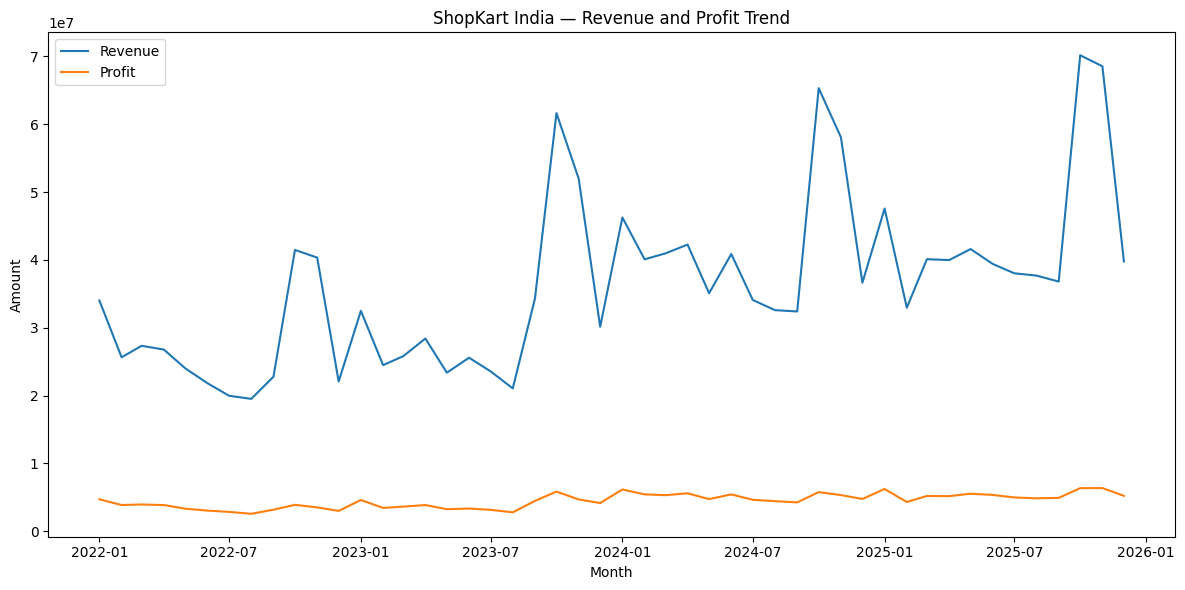

In [42]:
# 1. Revenue and profit trend
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly["month"], monthly["revenue"], label="Revenue")
ax.plot(monthly["month"], monthly["profit"], label="Profit")
ax.set_title("ShopKart India — Revenue and Profit Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
ax.legend()
save_figure("01_revenue_profit_trend.png")


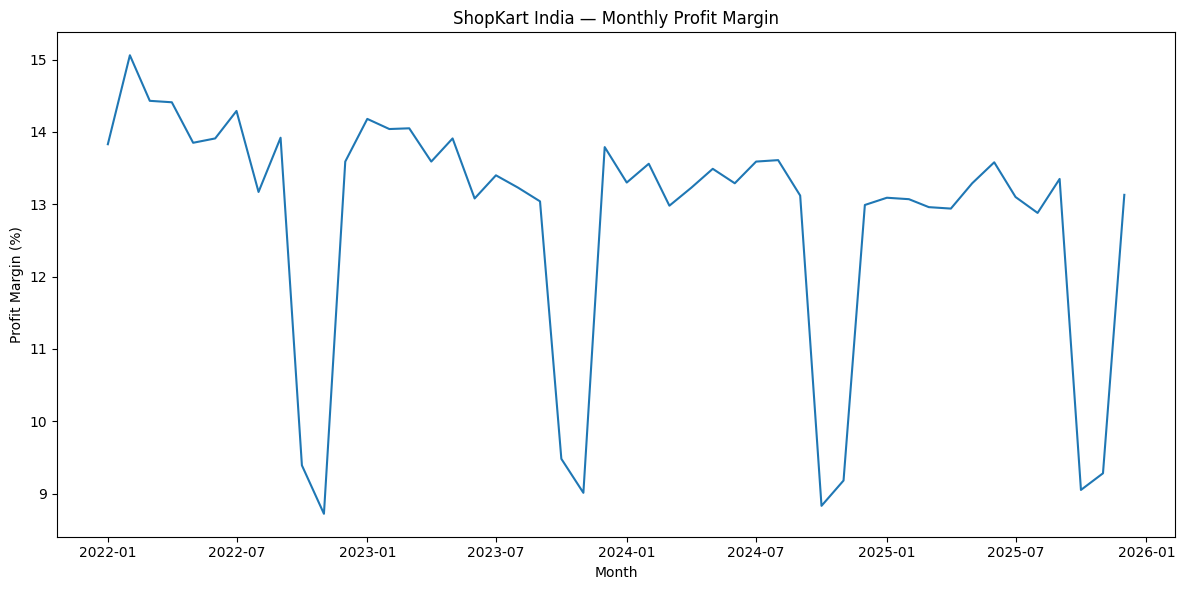

In [43]:
# 2. Monthly profit margin
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(monthly["month"], monthly["profit_margin_percent"])
ax.set_title("ShopKart India — Monthly Profit Margin")
ax.set_xlabel("Month")
ax.set_ylabel("Profit Margin (%)")
save_figure("02_profit_margin_trend.png")


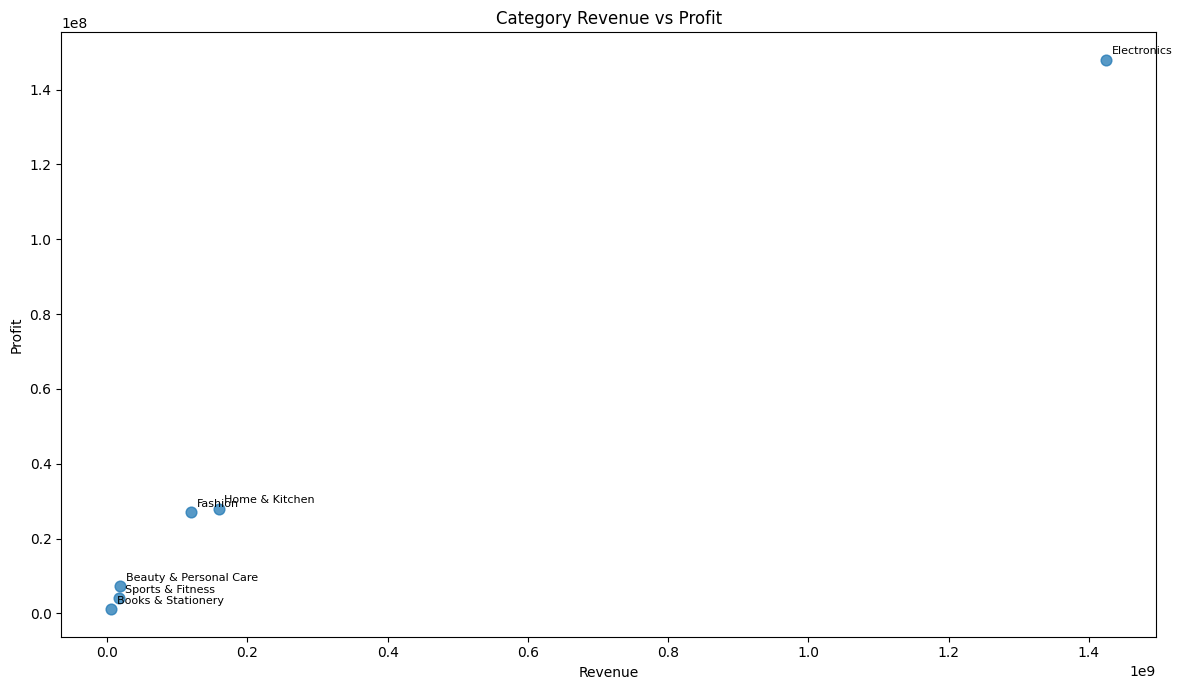

In [44]:
# 3. Category revenue vs profit
d = category_profitability.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(d["revenue"], d["profit"], s=60, alpha=0.75)

for _, row in d.iterrows():
    ax.annotate(
        row["category_name"],
        (row["revenue"], row["profit"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8
    )

ax.set_title("Category Revenue vs Profit")
ax.set_xlabel("Revenue")
ax.set_ylabel("Profit")
save_figure("03_category_revenue_vs_profit.png")


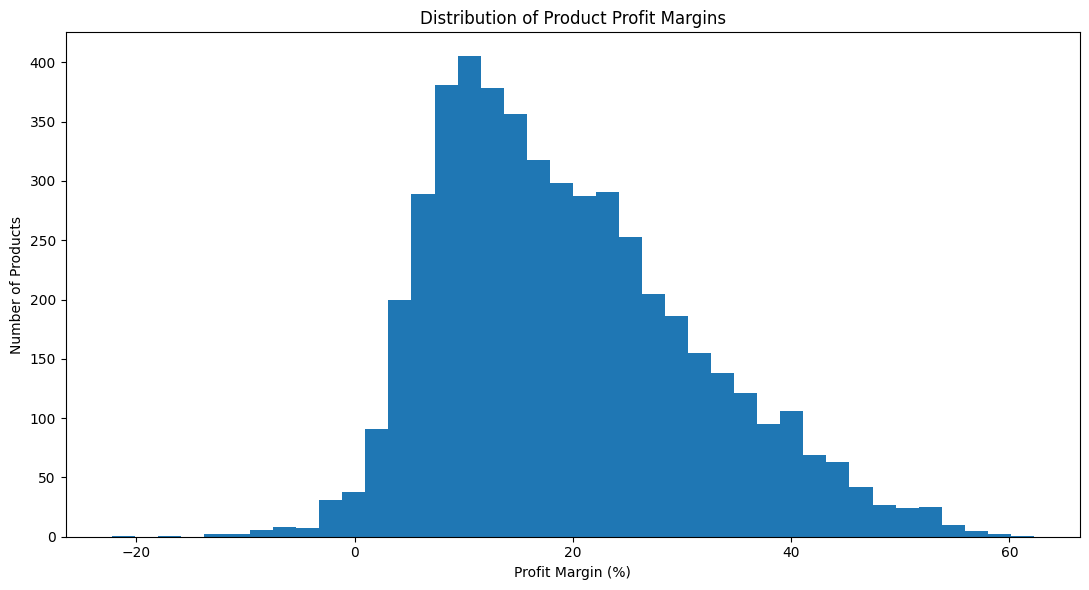

In [45]:
# 4. Product margin distribution
fig, ax = plt.subplots(figsize=(11, 6))
ax.hist(products["profit_margin_percent"].dropna(), bins=40)
ax.set_title("Distribution of Product Profit Margins")
ax.set_xlabel("Profit Margin (%)")
ax.set_ylabel("Number of Products")
save_figure("04_product_margin_distribution.png")


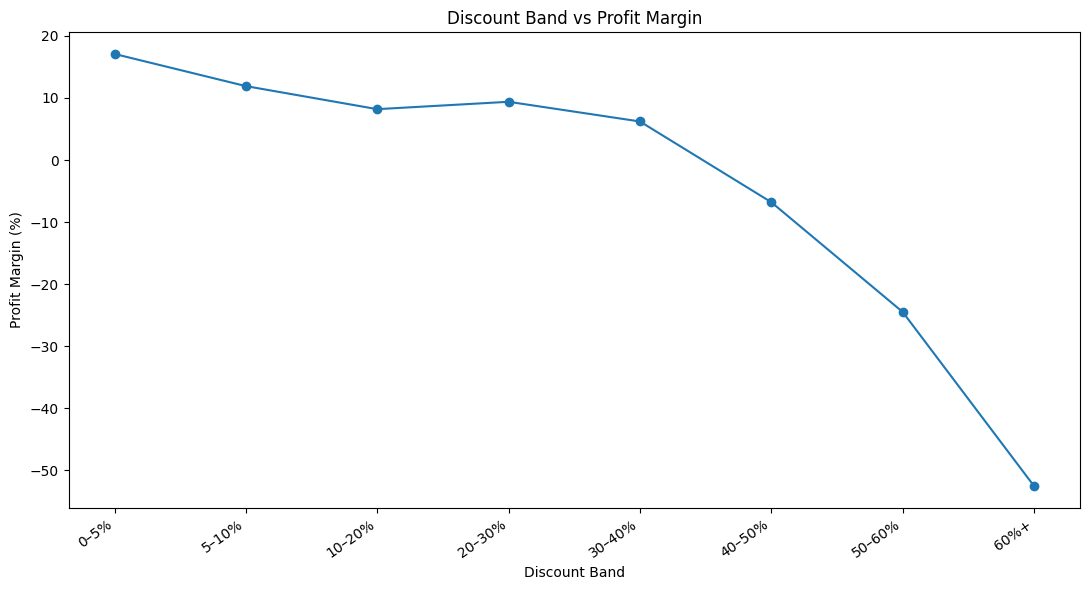

In [46]:
# 5. Discount band vs profit margin
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    discount_analysis["discount_band"].astype(str),
    discount_analysis["profit_margin_percent"],
    marker="o"
)
ax.set_title("Discount Band vs Profit Margin")
ax.set_xlabel("Discount Band")
ax.set_ylabel("Profit Margin (%)")
plt.xticks(rotation=35, ha="right")
save_figure("05_discount_vs_margin.png")


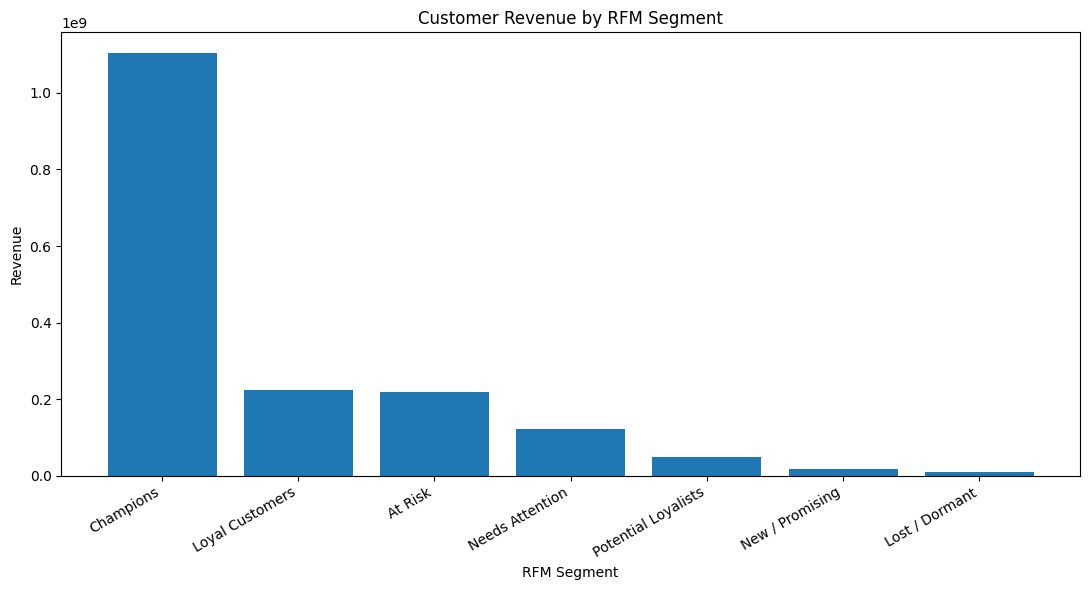

In [47]:
# 6. Revenue by RFM segment
d = rfm_segment_value.sort_values("revenue", ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(d["rfm_segment"], d["revenue"])
ax.set_title("Customer Revenue by RFM Segment")
ax.set_xlabel("RFM Segment")
ax.set_ylabel("Revenue")
plt.xticks(rotation=30, ha="right")
save_figure("06_rfm_segment_revenue.png")


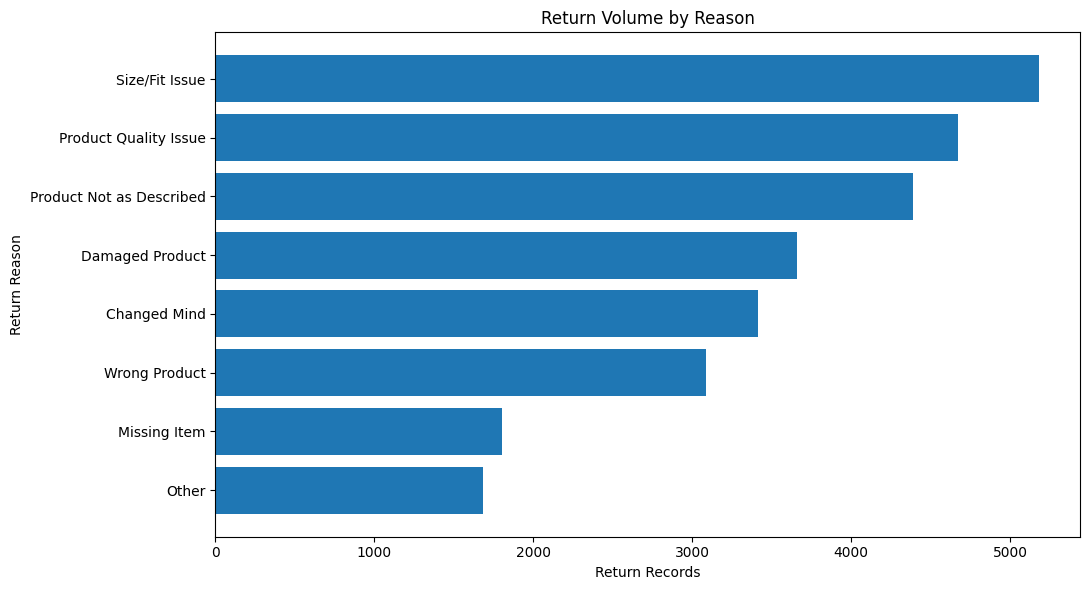

In [48]:
# 7. Return reasons

return_reason_chart = (
    returns.groupby("return_reason")
    .agg(
        returns=("return_id", "nunique"),
        refund_amount=("refund_amount", "sum"),
        return_cost=("return_cost", "sum")
    )
    .reset_index()
    .sort_values("returns", ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    return_reason_chart["return_reason"],
    return_reason_chart["returns"]
)

ax.set_title("Return Volume by Reason")
ax.set_xlabel("Return Records")
ax.set_ylabel("Return Reason")

save_figure("07_return_reasons.png")

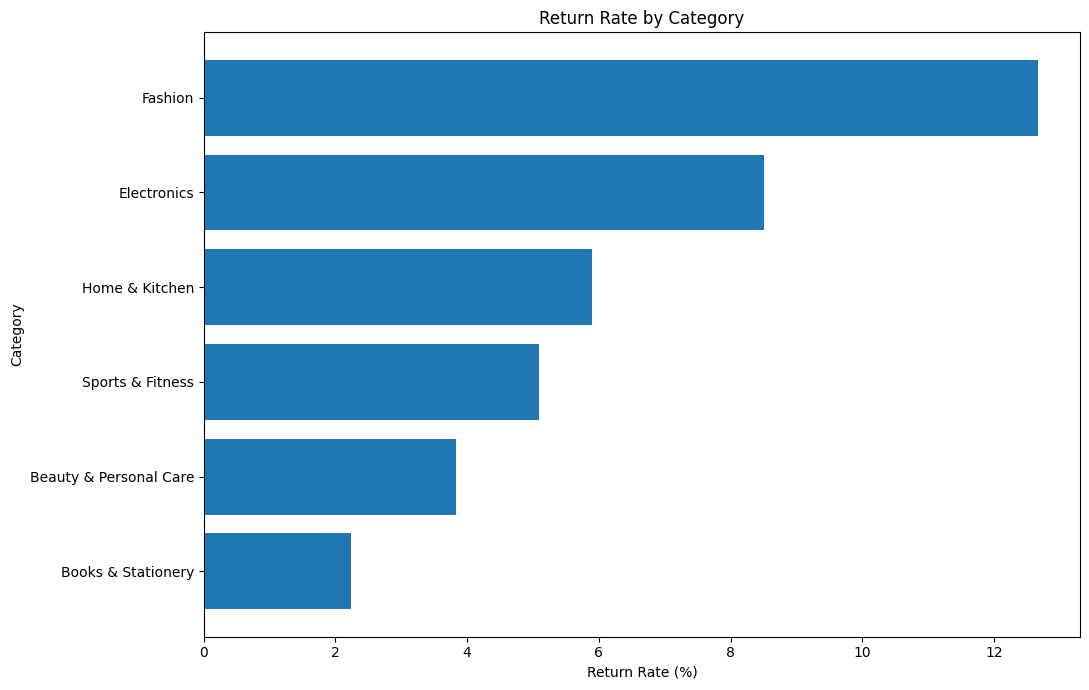

In [49]:
# 8. Category return rate
d = category_return.sort_values("return_rate_percent", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(d["category_name"], d["return_rate_percent"])
ax.set_title("Return Rate by Category")
ax.set_xlabel("Return Rate (%)")
ax.set_ylabel("Category")
save_figure("08_category_return_rate.png")


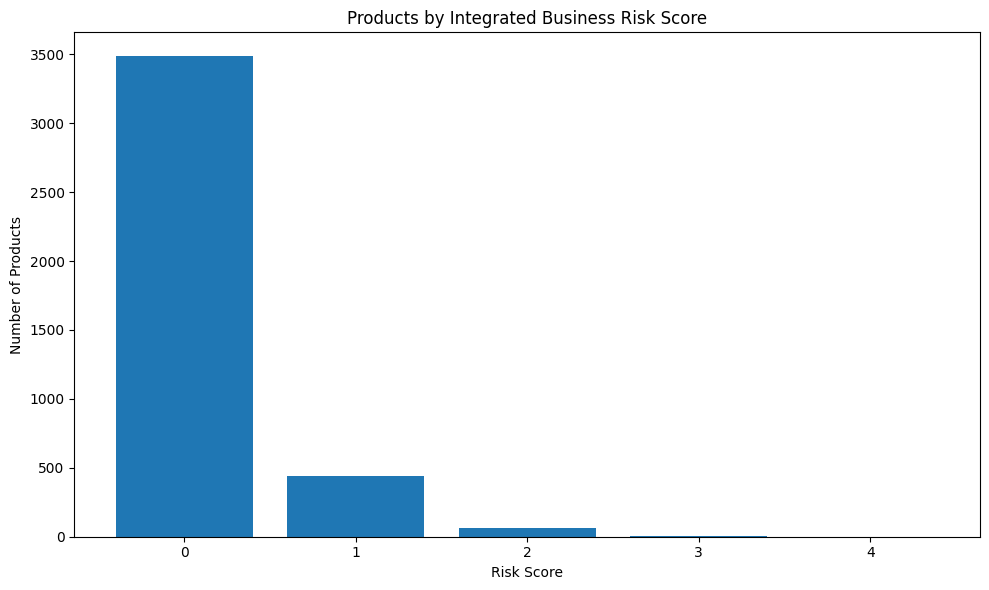

In [50]:
# 9. Integrated product risk score
risk_counts = eligible["business_risk_score"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(risk_counts.index.astype(str), risk_counts.values)
ax.set_title("Products by Integrated Business Risk Score")
ax.set_xlabel("Risk Score")
ax.set_ylabel("Number of Products")
save_figure("09_product_risk_score.png")


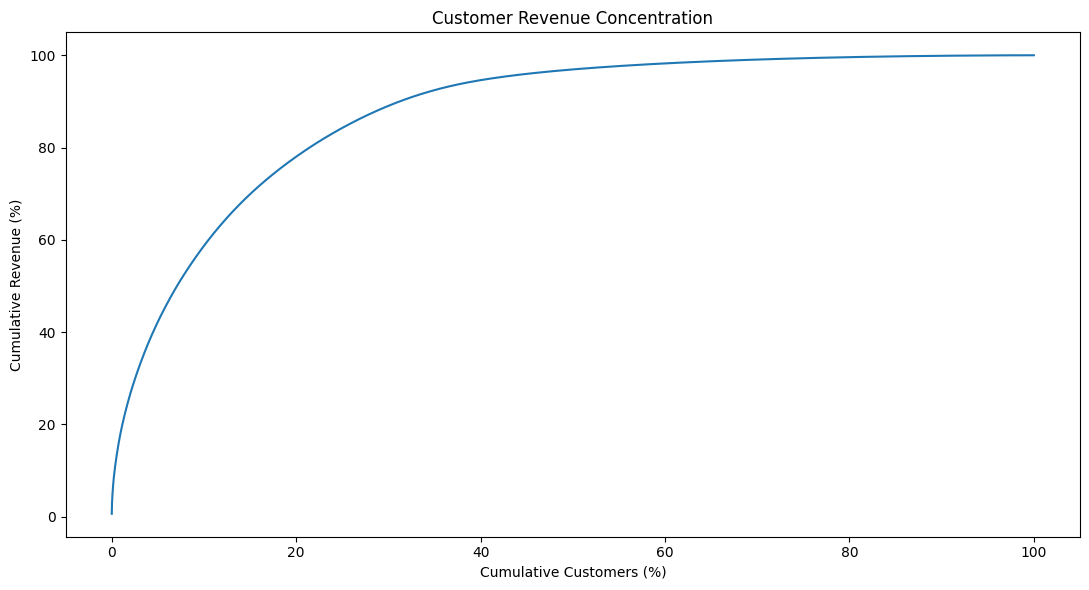

In [51]:
# 10. Customer revenue concentration
curve = rfm_sorted.reset_index(drop=True).copy()
curve["customer_percent"] = (curve.index + 1) / len(curve) * 100
curve["cumulative_revenue_percent"] = (
    curve["monetary"].cumsum() /
    curve["monetary"].sum() * 100
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(curve["customer_percent"], curve["cumulative_revenue_percent"])
ax.set_title("Customer Revenue Concentration")
ax.set_xlabel("Cumulative Customers (%)")
ax.set_ylabel("Cumulative Revenue (%)")
save_figure("10_customer_revenue_concentration.png")


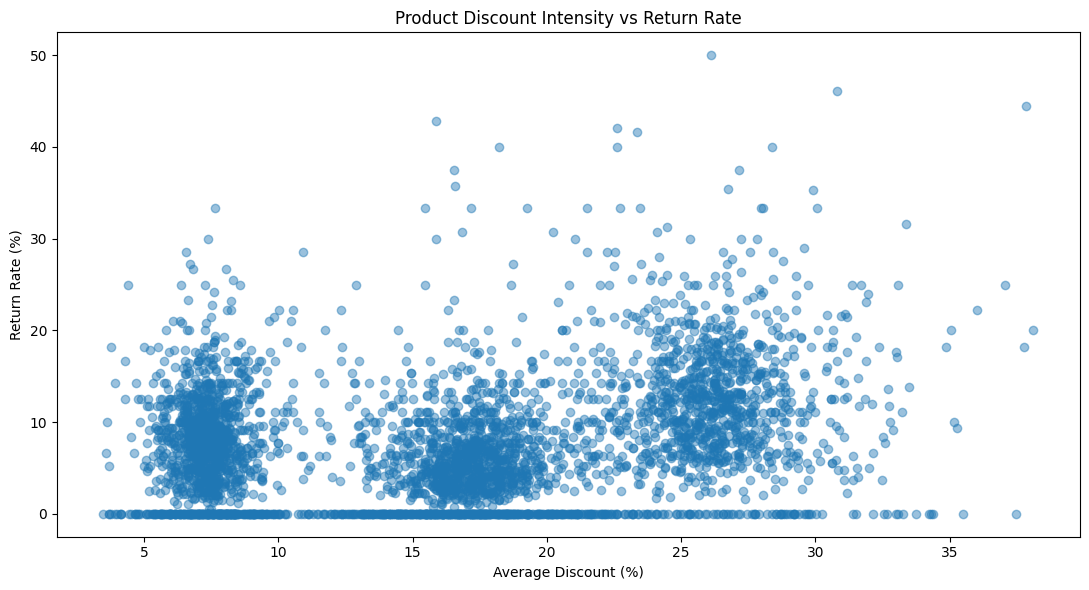

In [52]:
# 11. Discount vs return rate
d = eligible[["avg_discount_percent", "return_rate_percent"]].dropna()

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(d["avg_discount_percent"], d["return_rate_percent"], alpha=0.45)
ax.set_title("Product Discount Intensity vs Return Rate")
ax.set_xlabel("Average Discount (%)")
ax.set_ylabel("Return Rate (%)")
save_figure("11_discount_vs_return_rate.png")


## 12. Final Business Findings

In [53]:
# Evidence table 1 — annual performance
final_annual = annual_from_monthly[[
    "year", "orders", "customers", "units_sold",
    "revenue", "profit", "profit_margin_percent",
    "discount", "revenue_growth_percent", "profit_growth_percent"
]]
display(final_annual)


,year,orders,customers,units_sold,revenue,profit,profit_margin_percent,discount,revenue_growth_percent,profit_growth_percent
0,2022,22921,16754,70318,"325,777,401.00","41,740,026.22",12.81,"34,247,851.00",NaN,NaN
1,2023,32346,25060,100806,"382,878,026.00","47,238,526.75",12.34,"43,529,208.00",17.53,13.17
2,2024,43133,34370,134394,"504,674,061.00","61,843,820.00",12.25,"55,558,415.00",31.81,30.92
3,2025,51600,41424,160054,"532,642,945.00","64,473,158.47",12.10,"63,186,351.00",5.54,4.25


In [54]:
# Evidence table 2 — highest-priority product opportunities
final_product_opportunities = risk_products[[
    "product_id", "product_name", "category_name",
    "units_sold", "revenue", "profit",
    "profit_margin_percent", "avg_discount_percent",
    "return_rate_percent", "total_return_impact",
    "business_risk_score"
]].head(25)

display(final_product_opportunities)


,product_id,product_name,category_name,units_sold,revenue,profit,profit_margin_percent,avg_discount_percent,return_rate_percent,total_return_impact,business_risk_score
663,PROD000676,Denimo Sneakers 598,Fashion,11,"8,050.00",-300.10,-3.73,38.12,20.00,"1,502.90",4
2723,PROD002767,Chic Route Sunglasses 927,Fashion,90,"88,957.00","-10,588.40",-11.90,30.89,14.63,"17,631.86",3
4560,PROD004639,Silkline Thermal Wear 559,Fashion,50,"58,762.00",-552.00,-0.94,33.06,0.00,0.00,3
1233,PROD001255,Denimo Sandals 222,Fashion,45,"19,775.00",-126.25,-0.64,27.68,23.68,"5,749.92",3
1402,PROD001425,Fabrico Kids Shorts 126,Fashion,10,"15,290.00",395.90,2.59,31.71,25.00,"3,714.06",3
3669,PROD003730,Chic Route Kids Shorts 834,Fashion,31,"12,054.00",-124.35,-1.03,30.69,12.50,"1,830.57",3
4107,PROD004179,Weardrobe Men's Jeans 443,Fashion,12,"9,587.00",-76.96,-0.80,27.22,30.00,"3,157.47",3
2236,PROD002270,Silkline Wallet 819,Fashion,10,"5,103.00",-267.00,-5.23,32.77,10.00,478.42,3
772,PROD000788,Metrostyle Analog Watch 428,Fashion,10,"2,832.00",112.10,3.96,36.01,22.22,487.10,3
733,PROD000747,Nirvana Fits Thermal Wear 869,Fashion,221,"442,555.00","-2,693.70",-0.61,27.37,8.57,"54,109.47",2


In [55]:
# Evidence table 3 — customer segments
final_customer_segments = rfm_segment_value[[
    "rfm_segment", "customers", "customer_share_percent",
    "revenue", "revenue_share_percent", "profit",
    "discount", "avg_recency_days", "avg_frequency", "avg_monetary"
]].sort_values("revenue", ascending=False)

display(final_customer_segments)


,rfm_segment,customers,customer_share_percent,revenue,revenue_share_percent,profit,discount,avg_recency_days,avg_frequency,avg_monetary
1,Champions,5145,18.98,"1,103,004,760.00",63.17,"135,066,475.91","122,096,253.00",40.93,17.09,"214,383.82"
3,Loyal Customers,3323,12.26,"225,071,562.00",12.89,"28,949,615.59","25,558,452.00",117.06,6.83,"67,731.44"
0,At Risk,4682,17.27,"219,887,073.00",12.59,"27,270,595.14","23,958,913.00",470.44,3.92,"46,964.35"
4,Needs Attention,5129,18.92,"122,160,408.00",7.00,"15,185,510.83","12,971,028.00",286.88,1.62,"23,817.59"
6,Potential Loyalists,2375,8.76,"48,667,298.00",2.79,"5,304,972.47","7,109,139.00",49.62,2.46,"20,491.49"
5,New / Promising,1942,7.16,"16,472,507.00",0.94,"1,671,082.64","2,591,898.00",51.08,1.03,"8,482.24"
2,Lost / Dormant,4509,16.64,"10,708,825.00",0.61,"1,847,278.86","2,236,142.00",566.87,1.08,"2,374.99"


In [56]:
# Evidence table 4 — return problem areas
final_return_categories = category_return.sort_values(
    "total_return_impact", ascending=False
)
display(final_return_categories)


,category_name,returned_items,return_records,refund_amount,return_cost,order_items,return_rate_percent,total_return_impact
2,Electronics,8190,8190,"105,946,718.00","20,391,580.81",96197,8.51,"126,338,298.81"
3,Fashion,13906,13906,"12,725,959.00","3,112,945.51",109720,12.67,"15,838,904.51"
4,Home & Kitchen,3645,3645,"7,564,638.00","1,549,601.56",61858,5.89,"9,114,239.56"
5,Sports & Fitness,633,633,"812,223.00","168,967.67",12439,5.09,"981,190.67"
0,Beauty & Personal Care,1248,1248,"622,562.00","173,416.54",32532,3.84,"795,978.54"
1,Books & Stationery,259,259,"98,623.00","35,683.77",11560,2.24,"134,306.77"


In [57]:
# Evidence table 5 — discount effectiveness
final_discount = discount_analysis[[
    "discount_band", "orders", "units_sold", "revenue",
    "profit", "discount", "profit_margin_percent",
    "revenue_share_percent"
]]
display(final_discount)


,discount_band,orders,units_sold,revenue,profit,discount,profit_margin_percent,revenue_share_percent
0,0–5%,56393,94392,"658,454,886.00","112,543,834.87","10,073,822.00",17.09,37.71
1,5–10%,42546,67801,"448,929,886.00","53,469,778.73","35,979,943.00",11.91,25.71
2,10–20%,69084,128053,"462,777,647.00","37,936,813.61","75,399,120.00",8.20,26.51
3,20–30%,50493,90274,"114,723,286.00","10,766,420.81","36,415,090.00",9.38,6.57
4,30–40%,32364,53246,"41,987,748.00","2,608,754.74","22,011,396.00",6.21,2.40
5,40–50%,15746,24056,"15,389,275.00","-1,045,038.71","12,193,609.00",-6.79,0.88
6,50–60%,4861,7019,"3,433,719.00","-840,125.45","3,988,752.00",-24.47,0.20
7,60%+,505,731,"275,986.00","-144,907.16","460,093.00",-52.51,0.02
